# 02. Верификация конкретного POI: MobileNetV3 → эмбеддинги → галерея → отказ

Frozen **MobileNetV3-Small / IMAGENET1K_V1**: не обучаем classifier и не дообучаем backbone.
Используем все POI из фиксированного mapping. Эталонные фото — только train;
пороги cosine и отрыва от другого POI — только val. Test оцениваем после фиксации порогов.
Нет искусственного unknown-класса и нет bbox. Все вычисления локальны, исходные фото не изменяются.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage

ROOT = Path.cwd().resolve()
if not (ROOT/'config/baseline_mobilenetv3.json').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.poi_baseline import (load_splits, run_baseline, POIVerifier, sha256_file)
OUTPUT = ROOT/'models/baseline_mobilenetv3'
CONFIG = ROOT/'config/baseline_mobilenetv3.json'
WEIGHTS = ROOT/'.runtime/torch/checkpoints/mobilenet_v3_small-047dcff4.pth'
splits, mapping = load_splits(ROOT)
display(pd.DataFrame({name:frame.groupby('poi_id').size() for name,frame in splits.items()}))
print('POI:', len(mapping), 'SEED=42')


,train,val,test
poi_id,,,
moscow/arbat/arseny_morozov_house,34,7,7
moscow/arbat/pashkov_house,35,8,7
moscow/khamovniki/khrushchev_seleznev_house,23,5,5
moscow/khamovniki/pushkin_museum,26,6,6
moscow/ostankinskiy/armenia,30,6,6
moscow/ostankinskiy/central_pavilion,26,6,6
moscow/ostankinskiy/cosmos,35,8,7
moscow/ostankinskiy/friendship_of_the_peoples,35,8,7
moscow/ostankinskiy/kazakhstan_pavilion,98,21,21


POI: 23 SEED=42


## 1. Веса, извлечение эмбеддингов и галерея

Предобученные веса должны быть доступны локально; сеть из ноутбука автоматически не вызывается.
При необходимости один раз запустите CLI с `--download-weights` (около 10 MB).
Изображение: первый кадр MPO → EXIF orientation → RGB → resize 256 → center crop 224 → ImageNet normalization.
После `features → avgpool → flatten` получаем 576D и L2-нормируем.
Эталонов максимум 20 на POI: farthest-first из train, по одному кадру группы на POI.
Автор, источник и лицензия каждой фотографии сохраняются в gallery.csv и snapshots splits.

Повторный Run All использует существующий зафиксированный выпуск и проверяет его хэши.
Для нового эксперимента задайте новую OUTPUT-папку; не подбирайте параметры по test.


In [2]:
if (OUTPUT/'metadata.json').exists():
    metadata = json.loads((OUTPUT/'metadata.json').read_text(encoding='utf-8'))
    for name in splits:
        assert sha256_file(ROOT/f'data/annotations/{name}.csv') == metadata['split_sha256'][name], 'Датасет изменён: нужен новый выпуск'
    assert json.loads(CONFIG.read_text(encoding='utf-8')) == json.loads((OUTPUT/'config.json').read_text(encoding='utf-8')), 'Конфигурация изменена: нужен новый выпуск'
    for name, digest in metadata['artifact_sha256'].items():
        assert sha256_file(OUTPUT/name) == digest, f'Изменён артефакт: {name}'
    assert sha256_file(ROOT/'data/annotations/class_mapping.json') == metadata['class_mapping_sha256']
    policy = json.loads((OUTPUT/'rejection_policy.json').read_text(encoding='utf-8'))
    metrics = json.loads((OUTPUT/'metrics.json').read_text(encoding='utf-8'))
    print('Использован зафиксированный выпуск; хэши проверены.')
else:
    metadata, policy, metrics = run_baseline(ROOT, OUTPUT, WEIGHTS, CONFIG)
gallery = pd.read_csv(OUTPUT/'gallery.csv', keep_default_na=False)
display(gallery.groupby('poi_id').agg(references=('image_id','size')))
display(gallery[['image_id','poi_id','source','author','licence']].head())
print('Embedding dimension:', metadata['embedding_dim'], 'Reference version:', metadata['reference_version'])


Использован зафиксированный выпуск; хэши проверены.


,references
poi_id,
moscow/arbat/arseny_morozov_house,20
moscow/arbat/pashkov_house,20
moscow/khamovniki/khrushchev_seleznev_house,20
moscow/khamovniki/pushkin_museum,20
moscow/ostankinskiy/armenia,20
moscow/ostankinskiy/central_pavilion,20
moscow/ostankinskiy/cosmos,20
moscow/ostankinskiy/friendship_of_the_peoples,20
moscow/ostankinskiy/kazakhstan_pavilion,20


,image_id,poi_id,source,author,licence
0,wm_d278caa4f75eb01d,moscow/arbat/arseny_morozov_house,wikimedia_commons,Tatiana El-Bakri,CC BY-SA 2.0
1,wm_59c8de5bc1409546,moscow/arbat/arseny_morozov_house,wikimedia_commons,Mike1979 Russia,CC BY-SA 4.0
2,wm_5d6536ae4516d652,moscow/arbat/arseny_morozov_house,wikimedia_commons,sailko,CC BY-SA 3.0
3,wm_d55c42b1e80697eb,moscow/arbat/arseny_morozov_house,wikimedia_commons,This file comes from the official website of t...,CC BY 4.0
4,wm_d1f1f53d24c87570,moscow/arbat/arseny_morozov_house,wikimedia_commons,"Andrey Filippov 安德烈 from Moscow, Russia",CC BY 2.0


Embedding dimension: 576 Reference version: 64282c8db70a-37bbbca65dee


## 2. Калибровка отказа только на val

`score(target)` — max cosine с эталонами цели; `margin` — разница с лучшим другим POI.
Принимаем только при прохождении обоих порогов и строго положительном margin.
Каждое val-фото даёт одну правильную цель и C−1 ошибочных запросов известных POI.
Выбираем максимальный true accept rate при эмпирическом known-wrong FAR ≤1%
и hard-wrong FAR ≤5% (по одному наиболее похожему неверному POI на фото).
Это не вероятность, не гарантия FAR и не калибровка отказа на посторонних объектах.
Пары одного фото зависимы; объём независимой выборки равен числу изображений/групп.


In [3]:
display(pd.Series(policy, name='val-only policy'))
display(pd.DataFrame(metrics).T[['query_count','top1_accuracy','macro_top1_accuracy','true_accept_rate','false_reject_rate','known_wrong_far','hard_wrong_far']])


score_threshold                                                         0.382125
margin_threshold                                                        0.023432
true_accept_rate                                                        0.635762
known_wrong_far                                                         0.002107
hard_wrong_far                                                          0.046358
tp                                                                            96
fp                                                                             7
calibration_split                                                            val
target_known_wrong_far                                                      0.01
target_hard_wrong_far                                                       0.05
negative_scope                                      other_known_poi_targets_only
external_unknown_calibrated                                                False
score_type                  

,query_count,top1_accuracy,macro_top1_accuracy,true_accept_rate,false_reject_rate,known_wrong_far,hard_wrong_far
val,151,0.788079,0.751501,0.635762,0.364238,0.002107,0.046358
test,146,0.746575,0.772257,0.664384,0.335616,0.002802,0.061644


## 3. Test после фиксации политики: качество и ошибки

Top-1 показывает только выбор лидера. Для задачи подтверждения цели нужны true accept rate,
false reject rate и known-wrong FAR. Внешний open-set FAR пока не измерен.


,poi_id,query_count,top1_accuracy,true_accept_rate,known_wrong_far,true_accepts,wrong_accepts
0,moscow/arbat/arseny_morozov_house,7,1.000000,1.000000,0.000000,7,0
1,moscow/arbat/pashkov_house,7,0.857143,0.857143,0.000000,6,0
2,moscow/khamovniki/khrushchev_seleznev_house,5,1.000000,0.600000,0.000000,3,0
3,moscow/khamovniki/pushkin_museum,6,0.500000,0.333333,0.007143,2,1
4,moscow/ostankinskiy/armenia,6,0.666667,0.666667,0.000000,4,0
5,moscow/ostankinskiy/central_pavilion,6,0.666667,0.666667,0.000000,4,0
6,moscow/ostankinskiy/cosmos,7,0.857143,0.857143,0.007194,6,1
7,moscow/ostankinskiy/main_entrance,7,0.714286,0.571429,0.000000,4,0
8,moscow/ostankinskiy/moscow_sun,8,0.750000,0.625000,0.000000,5,0
9,moscow/ostankinskiy/ostankino_tower,10,0.900000,0.900000,0.000000,9,0


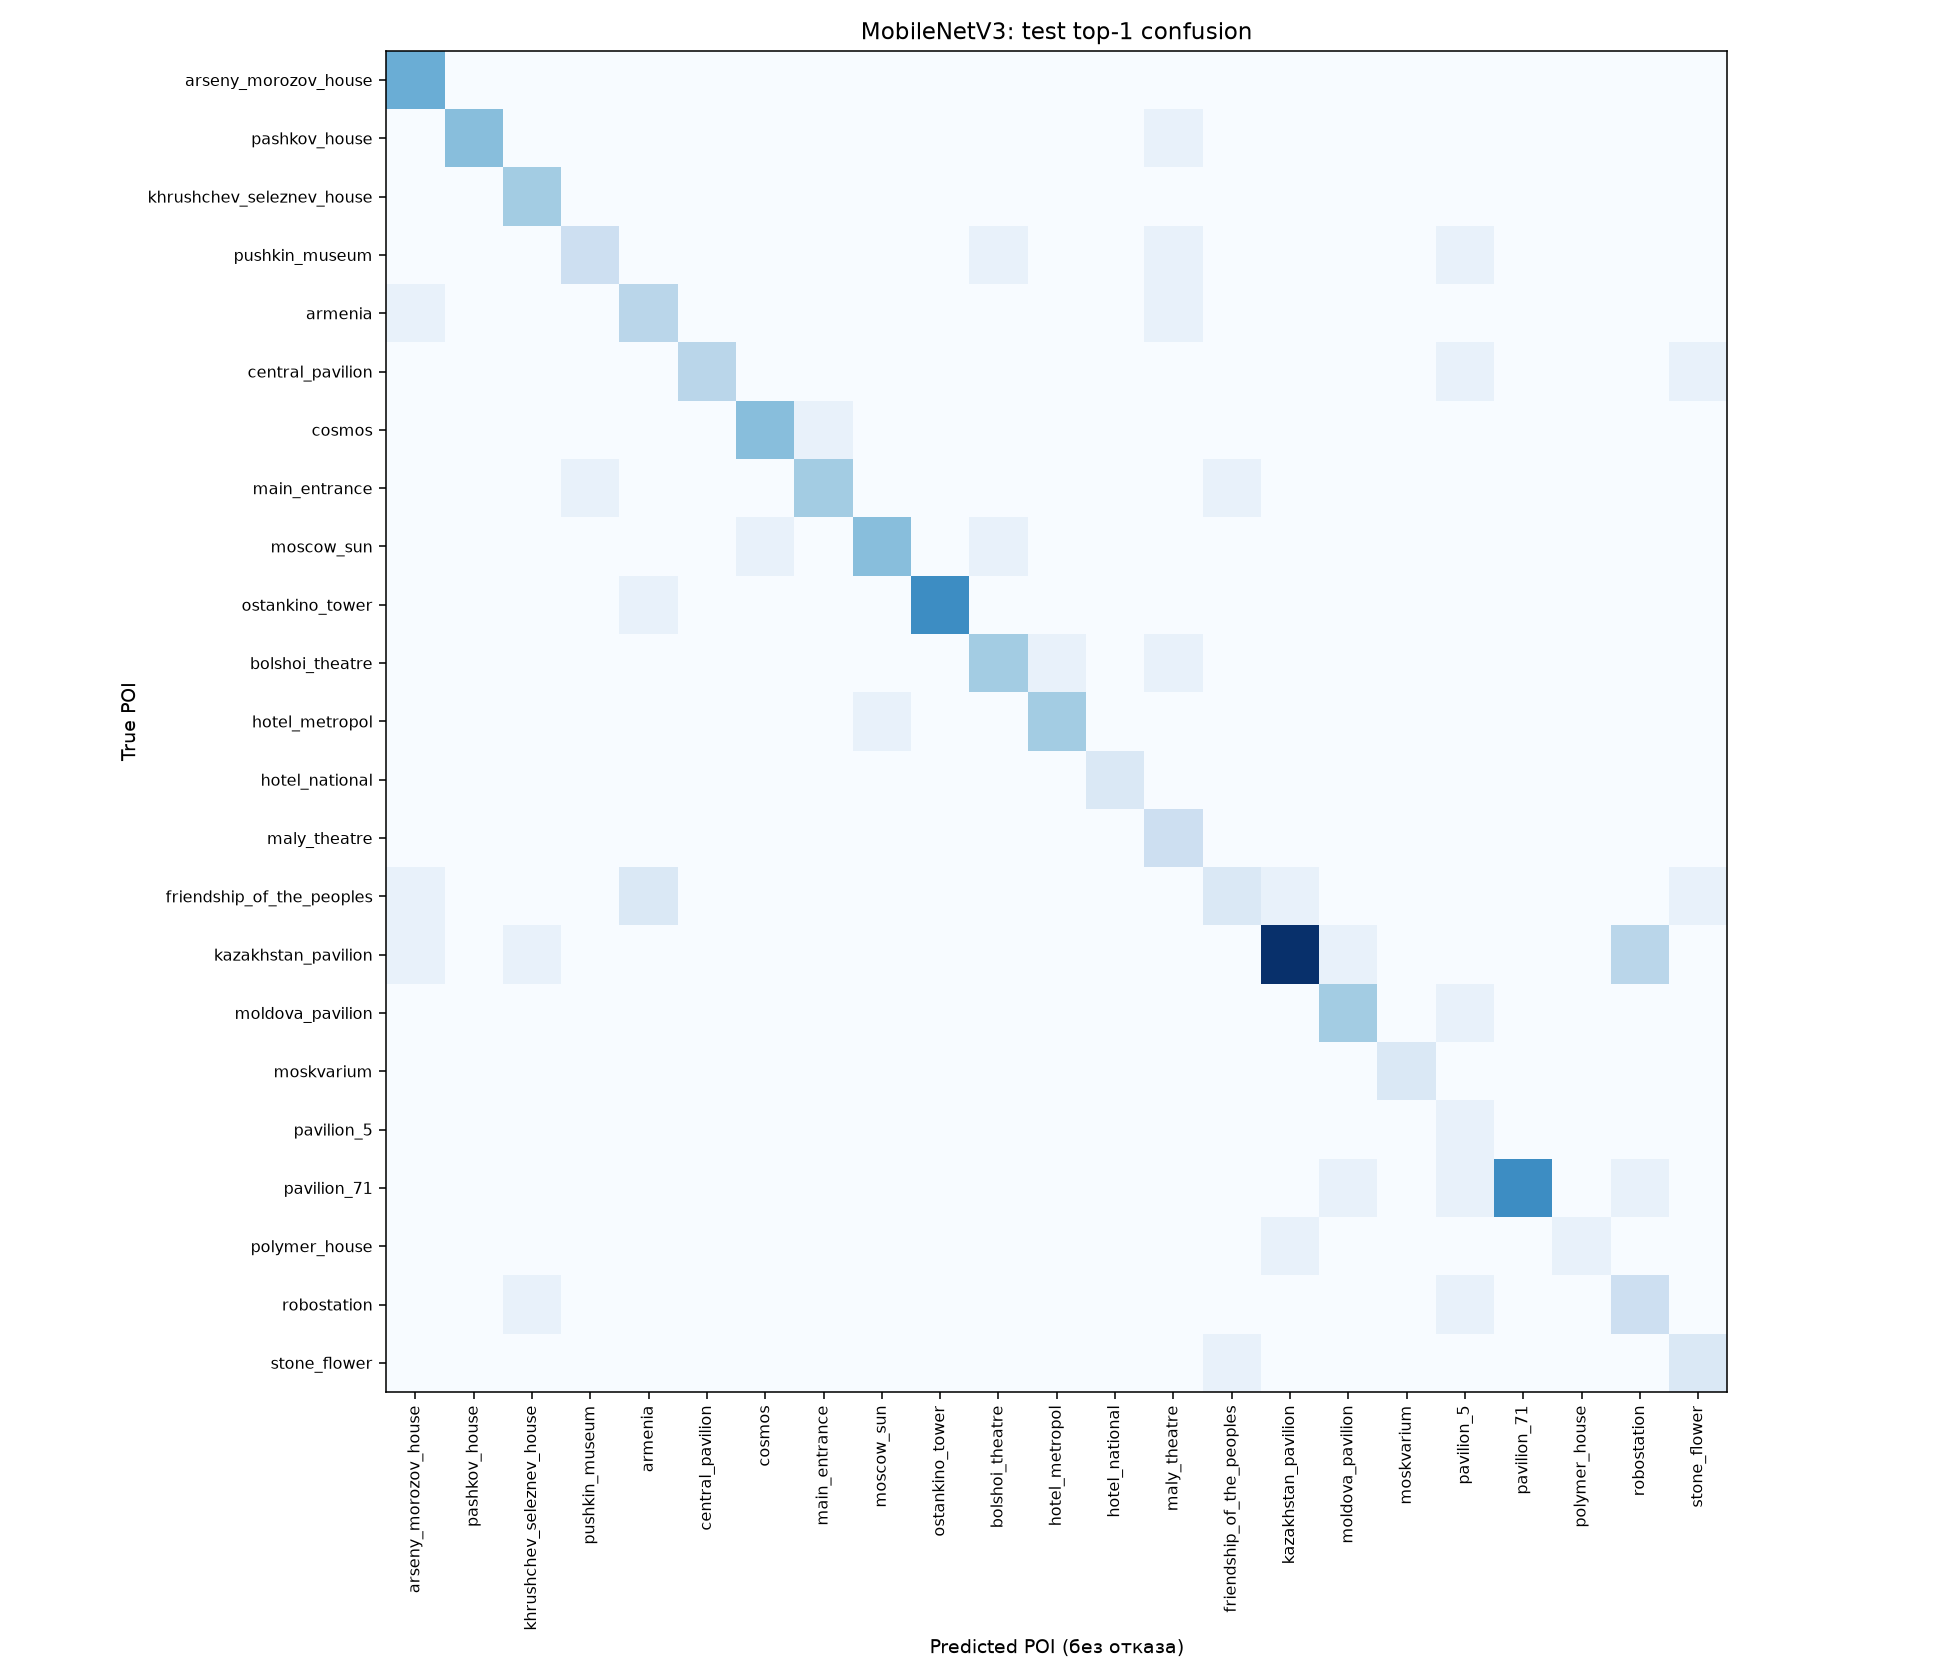

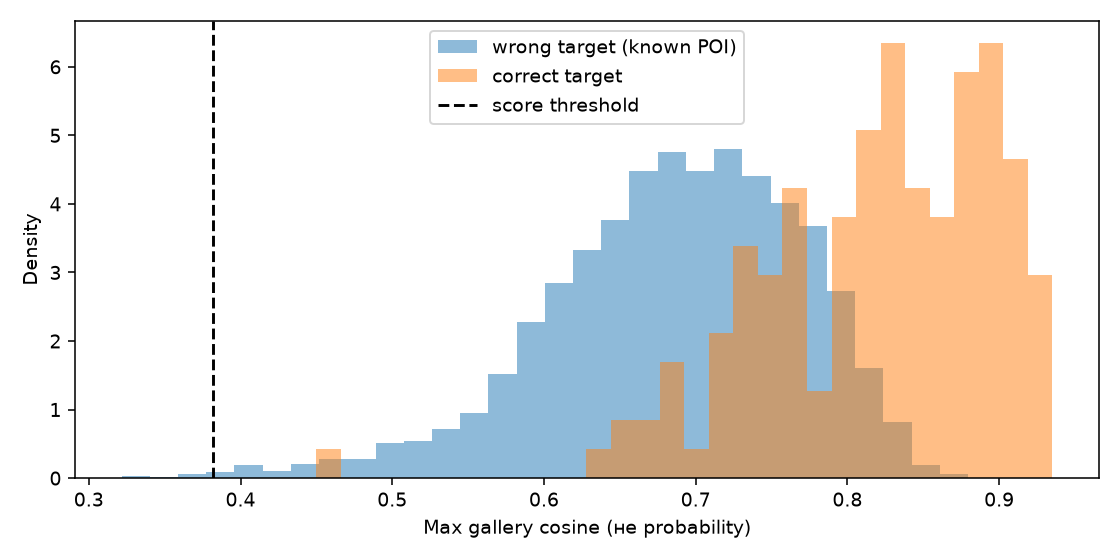

,image_id,source,true_poi_id,target_poi_id,genuine,accepted,score,margin,predicted_poi_id,reason,reference_image_id
14,manual_0155ae4a22c002c6,manual,moscow/ostankinskiy/friendship_of_the_peoples,moscow/ostankinskiy/friendship_of_the_peoples,True,False,0.756025,0.013188,moscow/ostankinskiy/friendship_of_the_peoples,poi_ambiguous,manual_64f68fdd6d8f76ae
107,manual_1349c09c770980dd,manual,moscow/ostankinskiy/kazakhstan_pavilion,moscow/ostankinskiy/kazakhstan_pavilion,True,False,0.793420,-0.016329,moscow/ostankinskiy/robostation,poi_not_matched,manual_fa1538903743d3ad
157,manual_15b3608a7700b553,manual,moscow/ostankinskiy/pavilion_71,moscow/ostankinskiy/pavilion_71,True,False,0.715790,-0.060712,moscow/ostankinskiy/moldova_pavilion,poi_not_matched,manual_33f38a57bbac588f
238,manual_23092ac15bcddba3,manual,moscow/ostankinskiy/moscow_sun,moscow/ostankinskiy/moscow_sun,True,False,0.741292,-0.015008,moscow/tverskoy/bolshoi_theatre,poi_not_matched,manual_7b09e6b0c0534113
268,manual_2560e5efd741d4f3,manual,moscow/ostankinskiy/kazakhstan_pavilion,moscow/ostankinskiy/kazakhstan_pavilion,True,False,0.673182,-0.071846,moscow/ostankinskiy/robostation,poi_not_matched,manual_2a983ba14796c5e1
274,manual_2560e5efd741d4f3,manual,moscow/ostankinskiy/kazakhstan_pavilion,moscow/ostankinskiy/robostation,False,True,0.745028,0.044180,moscow/ostankinskiy/robostation,poi_verified,manual_765b2ad6f30d0693
359,manual_3aae67e676b90367,manual,moscow/ostankinskiy/friendship_of_the_peoples,moscow/ostankinskiy/friendship_of_the_peoples,True,False,0.684272,-0.038402,moscow/ostankinskiy/kazakhstan_pavilion,poi_not_matched,manual_48844ca6798f48a9
360,manual_3aae67e676b90367,manual,moscow/ostankinskiy/friendship_of_the_peoples,moscow/ostankinskiy/kazakhstan_pavilion,False,True,0.722674,0.026999,moscow/ostankinskiy/kazakhstan_pavilion,poi_verified,manual_2ca8f817c271a413
383,manual_3ae4d74c55a7aa53,manual,moscow/ostankinskiy/kazakhstan_pavilion,moscow/ostankinskiy/kazakhstan_pavilion,True,False,0.449810,-0.133517,moscow/khamovniki/khrushchev_seleznev_house,poi_not_matched,manual_2a983ba14796c5e1
590,manual_59d630c871fb5167,manual,moscow/ostankinskiy/kazakhstan_pavilion,moscow/ostankinskiy/kazakhstan_pavilion,True,False,0.686244,-0.003548,moscow/ostankinskiy/robostation,poi_not_matched,manual_2a983ba14796c5e1


In [4]:
display(pd.read_csv(OUTPUT/'test_per_poi.csv'))
for name in ['test_confusion.png','test_score_distribution.png']:
    display(DisplayImage(filename=str(ROOT/'reports/baseline_mobilenetv3'/name)))
pairs = pd.read_csv(OUTPUT/'test_pairs.csv')
errors = pairs[(pairs.genuine & ~pairs.accepted) | (~pairs.genuine & pairs.accepted)]
display(errors.head(30))


## 4. Локальная проверка заданного POI

Передайте полный poi_id из mapping. Неизвестный галерее poi_id возвращает
`target_poi_not_supported`. Отрицательное решение сохраняет причины и ближайший эталон цели.
Выбранный ниже пример фиксирован по image_id и не отбирается по правильности ответа.


In [5]:
verifier = POIVerifier(OUTPUT)
example = splits['test'].iloc[0]
image_path = ROOT/(example.processed_path or example.file_path)
result = verifier.verify(image_path, example.poi_id)
display(pd.Series(result))
print('Все поддерживаемые POI:', list(mapping))
# Свой запрос:
# verifier.verify(Path('path/to/photo.jpg'), 'moscow/ostankinskiy/ostankino_tower')


accepted                                                             False
reason                                                       poi_ambiguous
target_poi_id                moscow/ostankinskiy/friendship_of_the_peoples
predicted_poi_id             moscow/ostankinskiy/friendship_of_the_peoples
score                                                             0.756025
margin                                                            0.013188
score_is_probability                                                 False
reference_image_id                                 manual_64f68fdd6d8f76ae
reference_source                                                    manual
reference_author                                             Shilkova A.M.
reference_licence                                            Public Domain
reference_version                                64282c8db70a-37bbbca65dee
threshold_version                                         5a64498995a872f5
preprocessing_version    

Все поддерживаемые POI: ['moscow/arbat/arseny_morozov_house', 'moscow/arbat/pashkov_house', 'moscow/khamovniki/khrushchev_seleznev_house', 'moscow/khamovniki/pushkin_museum', 'moscow/ostankinskiy/armenia', 'moscow/ostankinskiy/central_pavilion', 'moscow/ostankinskiy/cosmos', 'moscow/ostankinskiy/main_entrance', 'moscow/ostankinskiy/moscow_sun', 'moscow/ostankinskiy/ostankino_tower', 'moscow/tverskoy/bolshoi_theatre', 'moscow/tverskoy/hotel_metropol', 'moscow/tverskoy/hotel_national', 'moscow/tverskoy/maly_theatre', 'moscow/ostankinskiy/friendship_of_the_peoples', 'moscow/ostankinskiy/kazakhstan_pavilion', 'moscow/ostankinskiy/moldova_pavilion', 'moscow/ostankinskiy/moskvarium', 'moscow/ostankinskiy/pavilion_5', 'moscow/ostankinskiy/pavilion_71', 'moscow/ostankinskiy/polymer_house', 'moscow/ostankinskiy/robostation', 'moscow/ostankinskiy/stone_flower']


## 5. Готовность и следующие шаги

Baseline готов для локального сравнения подходов; production-готовность отказа не подтверждена.
Нужны отдельные проверенные unknown-val/unknown-test и независимые полевые фотографии.
Малые классы с одним test-фото не дают устойчивой оценки. Повторный выбор порогов по test запрещён.
Проверьте различия Wikimedia/manual, ошибки POI и лицензионную атрибуцию.
Ни аугментации, ни оптимизация весов на этом этапе не выполняются.

[Официальные веса и transforms TorchVision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html).


In [6]:
display(Markdown((ROOT/'reports/baseline_mobilenetv3/summary.md').read_text(encoding='utf-8')))


# Baseline верификации POI: MobileNetV3-Small

Обучение весов не выполнялось. Frozen ImageNet1K V1 → avgpool 576D → L2 → train-галерея → cosine + margin.
Артефакты: `models/baseline_mobilenetv3`.
POI: 23; эталонов: 404; SEED=42; CPU.

## Проверка целевого POI
score(target) = максимальный cosine с эталонами target. margin = score(target) − max score(других POI).
Подтверждаем при score ≥ 0.382125, margin ≥ 0.023432 и margin > 0. При равенстве лидеров — отказ.
Score не является вероятностью; confidence не выдумывается. Неизвестный галерее target возвращает отказ.

## Результаты
| Выборка | Фото | Top-1 | Macro Top-1 | True accept | Known-wrong FAR | Hard-wrong FAR |
|---|---:|---:|---:|---:|---:|---:|
| val (калибровка) | 151 | 78.81% | 75.15% | 63.58% | 0.21% | 4.64% |
| test (после фиксации порогов) | 146 | 74.66% | 77.23% | 66.44% | 0.28% | 6.16% |

## Наблюдение → интерпретация → действие
- Test: 97/146 верных подтверждений и 9/3212 ошибочных подтверждений чужой цели → измерена верификация среди известных POI → изучить test_pairs.csv и test_per_poi.csv.
- Пороги выбраны только на val: known-wrong FAR ≤1.0%, hard-wrong FAR ≤5.0% → это настройка baseline, не гарантия на новых данных → test не использовать для повторного подбора.
- Hard-wrong FAR использует для каждого фото наиболее похожий неверный POI; known-wrong FAR усредняет все C−1 неверных целей → множество лёгких пар может скрывать ошибки → оценивать оба показателя.
- На test hard-wrong FAR=6.16%, целевой val-предел=5.0% → ограничение на val не гарантирует качество новых фото → пороги текущего выпуска не менять; собирать независимую проверку и оценивать новый выпуск отдельно.
- Нет подтверждённого внешнего negative-набора → отказ на произвольных улицах, интерьерах и других достопримечательностях не измерен → собрать независимые unknown-val и unknown-test, затем выпустить новую версию порогов.
- В малых классах val/test содержат единичные кадры → оценки нестабильны; wrong-target пары одного фото зависимы → добрать независимые полевые серии; не трактовать число пар как число независимых фото.
- Пороговые и top-1 метрики отвечают разным вопросам → правильный лидер ещё может быть отклонён → оценивать true accept и FAR вместе.
- Разделение по источникам сохранено в metrics.json → возможен сдвиг Wikimedia/manual → дополнительно провести полевой тест с мобильных устройств.

## Воспроизводимость и ограничения
Галерея: детерминированный farthest-first из train, максимум 20 эталонов на POI и один кадр каждой split_group внутри POI (точный лимит в config.json).
CSV разбиения, атрибуция source/author/licence, веса, эмбеддинги, версии библиотек и SHA-256 артефактов сохранены рядом с metadata.json.
Проверены отсутствие пересечений ID/SHA/групп/серий/Commons-ID и хэши всех используемых фотографий. Исходники не изменены.
Побитовая воспроизводимость ожидается в зафиксированной CPU-среде; между версиями PyTorch/оборудованием возможны численные отличия.
Baseline пригоден для локальных экспериментов. Готовность к production-отказу на unknown не подтверждена.

[TorchVision: MobileNetV3-Small и преобразования весов](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html).
